# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Dylan Wang, Peter Cao, Lani Le

**Date:** 11/2/2026

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

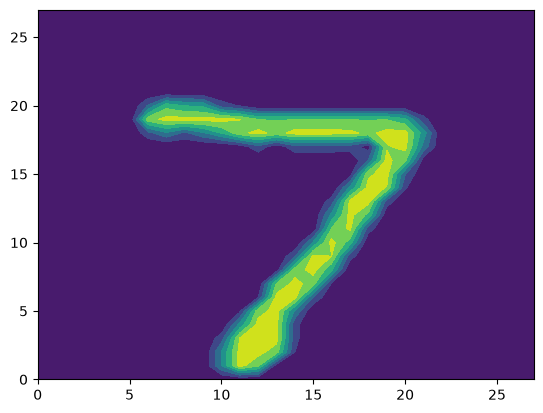

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

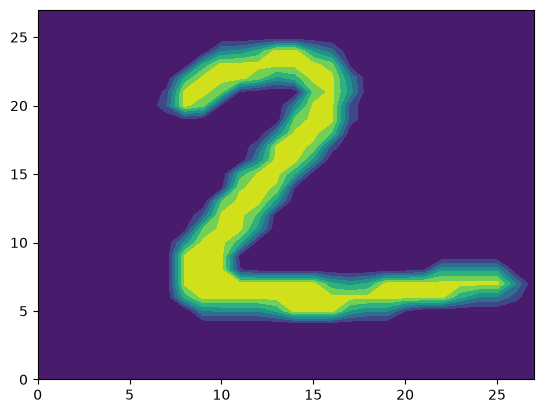

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

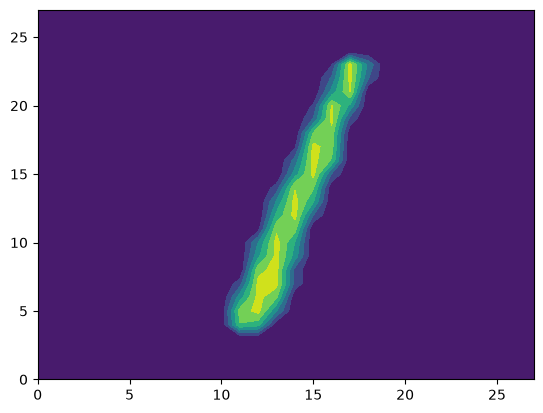

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

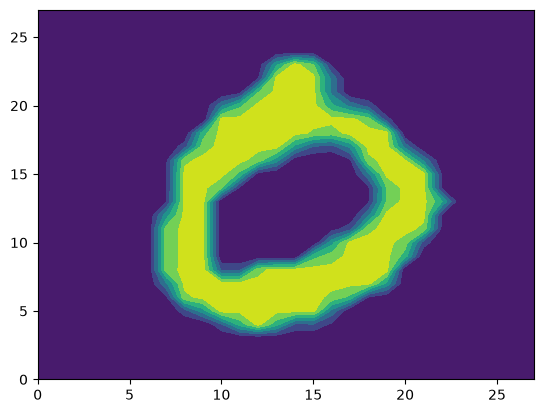

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

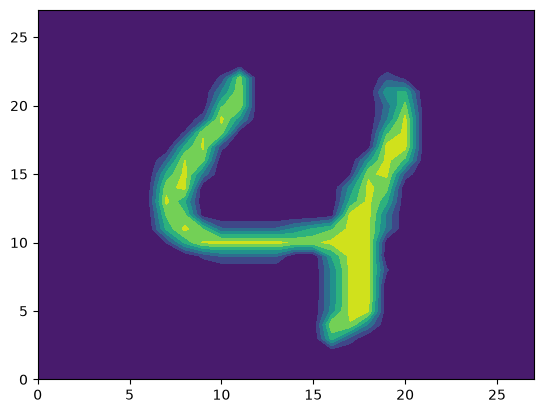

In [2]:
# Question 1, display the images and patterns
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()


In [3]:
# Question 2, shape of xtrain and xtest, shape of x_train[i] and x_test[i] for each index and y_train and y_test
# shape of x train and test
shape_xtrain = X_train.shape
shape_xtest = X_test.shape
print("X_Train shape: ", shape_xtrain)
print("x_Test shape: ", shape_xtest)


# get the shape for x_train[i] and x_test[i], since they all have the same shape, we can just print the shape of the first cell
shape_xtrain_i = X_train[0].shape
print(f"Index {0}: X_train shape: {shape_xtrain_i}")

shape_xtest_i = X_test[0].shape
print(f"Index {0}: X_test shape: {shape_xtest_i}")

# shape of y_train and y_test
shape_ytrain = y_train.shape
shape_ytest = y_test.shape
print("y_Train shape: ", shape_ytrain)
print("y_Test shape: ", shape_ytest)




X_Train shape:  (60000, 28, 28)
x_Test shape:  (10000, 28, 28)
Index 0: X_train shape: (28, 28)
Index 0: X_test shape: (28, 28)
y_Train shape:  (60000,)
y_Test shape:  (10000,)


In [4]:
# 3. Use Numpy's `.reshape()` method to convert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a 28 * 28=784-length row vector of values, rather than a matrix. Turn `X_train` into an n * 784 matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
# first we need to reshape the training and testing data into vectors of features. We can do this using numpy's reshape method.
reshaped_X_train = X_train.reshape(-1, 784)
reshaped_X_test = X_test.reshape(-1, 784)
print("reshaped_X_train shape: ", reshaped_X_train.shape)
print("reshaped_X_test shape: ", reshaped_X_test.shape)


reshaped_X_train shape:  (60000, 784)
reshaped_X_test shape:  (10000, 784)


In [7]:
# 4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
# we need to import k-nearest neighbors classifier from sklearn
import sklearn
import sklearn.neighbors
import sklearn.metrics
import sklearn.model_selection
from sklearn.neighbors import KNeighborsClassifier
 # type: ignore


# next we need to create a k-nearest neighbor classifier using the reshaped training data and the labels. We can do this using sklearn's KNeighborsClassifier class.
k_values = [1, 2, 3, 4, 5, 6, 7, 9]
# we will try all the tentative k values
for k in k_values:
    knn = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k)
    knn.fit(reshaped_X_train.reshape(reshaped_X_train.shape[0], 784), y_train)
    y_pred = knn.predict(reshaped_X_test.reshape(reshaped_X_test.shape[0], 784))
    accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)
    print(f"Accuracy for k={k}: {accuracy:.4f}")

# after running through the possible k values, we found that k = 3 has the highest accuracy



Accuracy for k=1: 0.9691
Accuracy for k=2: 0.9627
Accuracy for k=3: 0.9705
Accuracy for k=4: 0.9682
Accuracy for k=5: 0.9688
Accuracy for k=6: 0.9677
Accuracy for k=7: 0.9694
Accuracy for k=9: 0.9659


In [8]:
# 5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
# we found k = 3 is the most accurate one
best_knn_model = sklearn.neighbors.KNeighborsClassifier(n_neighbors=3)
best_knn_model.fit(reshaped_X_train.reshape(reshaped_X_train.shape[0], 784), y_train)
# the accuracy metrics 
y_pred = best_knn_model.predict(reshaped_X_test.reshape(reshaped_X_test.shape[0], 784))

accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)
conf_matrix = sklearn.metrics.confusion_matrix(y_test, y_pred)

print("Test accuracy for k=3: ", accuracy)
print("Confusion matrix for k=3: \n", conf_matrix)



Test accuracy for k=3:  0.9705
Confusion matrix for k=3: 
 [[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [  10    9  996    2    0    0    0   13    2    0]
 [   0    2    4  976    1   13    1    7    3    3]
 [   1    6    0    0  950    0    4    2    0   19]
 [   6    1    0   11    2  859    5    1    3    4]
 [   5    3    0    0    3    3  944    0    0    0]
 [   0   21    5    0    1    0    0  991    0   10]
 [   8    2    4   16    8   11    3    4  914    4]
 [   4    5    2    8    9    2    1    8    2  968]]


With k = 3, the classifier achieved 97.05% test accuracy. It correctly classified 9,705 of the 10,000 images and misclassified 295. Most entries in the confusion matrix are on the diagonal, and it shows that the model usually predicts the correct digit. However, this test set was also used to select k, so the accuracy is not a fully independent evaluation.

In [9]:
# 6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
errors = conf_matrix.copy()
np.fill_diagonal(errors, 0)

actual, predicted = np.unravel_index(errors.argmax(), errors.shape)

print("Most common mistake:", actual, "predicted as", predicted)
print("Count:", errors[actual, predicted])

Most common mistake: 7 predicted as 1
Count: 21


The most common mistake was predicting 7 as 1, which occurred 21 times. Other common mistakes were predicting 4 as 9 nineteen times and 8 as 3 sixteen times. The model also confused 3 and 5 in both directions: thirteen 3s were predicted as 5, and eleven 5s were predicted as 3. These digits can have similar handwritten shapes, which may explain the confusion. Digit 1 was recognized most reliably, with only two mistakes out of 1,135 images.

Q7:

I would represent a color photo using three matrices (the tri color), one each for red, green, and blue. Each matrix would contain values from 0 to 255. Together, they form an array with shape (height, width, 3). For example, a 28 × 28 color image would have shape (28, 28, 3). I would flatten this array into a vector containing 2,352 values. Each image would become one row in a table, with each column representing a particular pixel’s color channel. All images would need the same dimensions.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** `aa77865a953fcfbc280264d08c5f698f777caae8` (`Finished Phase 1`)
- **AI tool and model used:** Codex 6.1 sol


### *Prompts used

1. "scan through my code for phase 1, spot anything wrong or does not answer the question correctly, make improvements, give suggestions along with concrete code changes"

no follow ups questions


### *AI-proposed changes


1. Check if commit is pushed.
2. Choose k on a reproducible, stratified validation split of the training set; reserve the test set for final evaluation.
3. Flatten images once, compare the stated candidate k values, define a tie rule, and select the best validation result programmatically.
4. Refit on all training images and report test accuracy, correct/error counts, and a labeled confusion matrix.
5. Rank off-diagonal mistakes by count and report class-specific error rates; distinguish measured patterns from possible visual explanations.
6. Clarify array shapes, pixel ranges, RGB flattening, and limitations of the search.

### *Evaluation of AI suggestions



| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I have commited the changes. |
| 2 | Accept | Phase 1 correctly acknowledges test reuse, but that still makes its reported accuracy optimistic for model selection. Use an 80/20 stratified split of training data with seed 42. Question 4's reference to fitting on test data is interpreted as a wording error: fit on training data and evaluate on test data. |
| 3 | Accept | Phase 1's reshape is already correct; its later reshapes are redundant. Keep its candidate set, select from validation accuracy, and prefer smaller k if tied. This is best among tested values, not a proven global optimum. |
| 4 | Accept | Phase 1 reports accuracy and a confusion matrix correctly for its chosen model. Recompute these after validation-based selection and label rows as actual and columns as predicted. |
| 5 | Accept | Phase 1 computes only the largest error in code and writes the other counts manually. Generate rankings and per-class rates directly from the new confusion matrix so the explanation stays consistent with the results. |
| 6 | Accept | Phase 1's shapes and RGB answer are correct. Explicitly confirm the observed 0–255 pixel range (the prompt says 256), consistent flatten order, and the limits of a single validation split. |

#### Questions 1–3: Load, inspect, and flatten the images

Each observation is a 28 × 28 grayscale image. The supplied instructions say “first ten” but show a loop over five images; this solution displays ten. The first image's full pixel matrix is printed to show how intensities encode a digit. All 784 pixel features share the same 0–255 scale, so feature-wise standardization is not necessary here.

Matplotlib is building the font cache; this may take a moment.


X_train: shape=(60000, 28, 28), dtype=uint8
X_test: shape=(10000, 28, 28), dtype=uint8
y_train: shape=(60000,), dtype=uint8
y_test: shape=(10000,), dtype=uint8
Each training/test image: (28, 28) (28, 28)
Observed training pixel range: 0 to 255
First test image (label 7):
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 

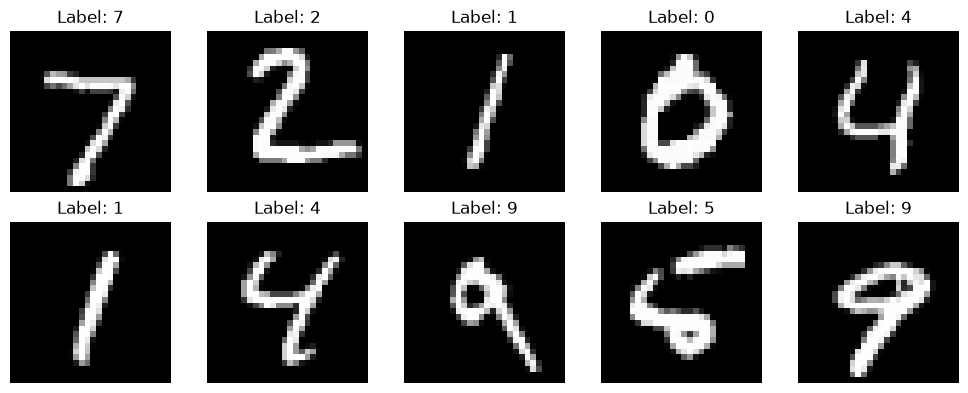

Flattened shapes: (60000, 784) (10000, 784)


In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits

with open("data/minst.pkl", "rb") as f:
    data = pickle.load(f)
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

for name, array in [("X_train", X_train), ("X_test", X_test),
                    ("y_train", y_train), ("y_test", y_test)]:
    print(f"{name}: shape={array.shape}, dtype={array.dtype}")
print("Each training/test image:", X_train[0].shape, X_test[0].shape)
print("Observed training pixel range:", X_train.min(), "to", X_train.max())
with np.printoptions(threshold=784, linewidth=120):
    print(f"First test image (label {y_test[0]}):\n{X_test[0]}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Label: {y_test[i]}")
    ax.axis("off")
fig.tight_layout()
plt.show()

# Float32 is sufficient for these pixel values and supports efficient distance calculation.
# Preserve the same row-major pixel order in training and test data.
X_train_flat = X_train.reshape(X_train.shape[0], -1).astype(np.float32)
X_test_flat = X_test.reshape(X_test.shape[0], -1).astype(np.float32)
assert X_train_flat.shape == (len(y_train), 784)
assert X_test_flat.shape == (len(y_test), 784)
assert np.array_equal(X_train_flat[0].reshape(28, 28), X_train[0])
print("Flattened shapes:", X_train_flat.shape, X_test_flat.shape)

The image arrays have shapes **(60,000, 28, 28)** and **(10,000, 28, 28)**. Every individual image has shape **(28, 28)**; labels have shapes **(60,000,)** and **(10,000,)**. Flattening produces **(60,000, 784)** and **(10,000, 784)** feature matrices. Labels remain separate from features.

#### Question 4: Select k using validation data

Hold out 12,000 training examples for validation and use the remaining 48,000 for fitting. Stratification preserves approximate digit proportions. Compare the same candidate values as Phase 1 using Euclidean distance and uniform voting. Neighbors are calculated once up to the largest candidate k; each smaller candidate uses the corresponding prefix. Votes are counted by digit, with the smallest digit winning a voting tie, matching scikit-learn's uniform-voting rule. If validation accuracies tie, choose the smaller k.

In [2]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train_flat, y_train, test_size=0.2, stratify=y_train, random_state=42
)
k_values = [1, 2, 3, 4, 5, 6, 7, 9]
search_model = KNeighborsClassifier(
    n_neighbors=max(k_values), weights="uniform", metric="euclidean", algorithm="brute"
)
search_model.fit(X_fit, y_fit)
# Limit threads to avoid excessive BLAS/OpenMP contention on some computers.
with threadpool_limits(limits=2):
    neighbor_indices = search_model.kneighbors(X_valid, return_distance=False)
neighbor_labels = y_fit[neighbor_indices]
validation_scores = {}
for k in k_values:
    votes = (neighbor_labels[:, :k, None] == np.arange(10)).sum(axis=1)
    predictions = votes.argmax(axis=1)
    validation_scores[k] = accuracy_score(y_valid, predictions)
    print(f"k={k}: validation accuracy={validation_scores[k]:.4%}")
best_k = max(k_values, key=lambda k: (validation_scores[k], -k))
print(f"Selected k={best_k}; validation accuracy={validation_scores[best_k]:.4%}")

# Verify prefix voting against the library's own prediction for the selected k.
check_model = KNeighborsClassifier(
    n_neighbors=best_k, weights="uniform", metric="euclidean", algorithm="brute"
).fit(X_fit, y_fit)
with threadpool_limits(limits=2):
    check_predictions = check_model.predict(X_valid[:200])
check_votes = (neighbor_labels[:200, :best_k, None] == np.arange(10)).sum(axis=1)
assert np.array_equal(check_predictions, check_votes.argmax(axis=1))

k=1: validation accuracy=97.0417%
k=2: validation accuracy=96.1500%
k=3: validation accuracy=97.0333%
k=4: validation accuracy=96.7333%
k=5: validation accuracy=96.7500%
k=6: validation accuracy=96.7333%
k=7: validation accuracy=96.6333%
k=9: validation accuracy=96.5417%
Selected k=1; validation accuracy=97.0417%


#### Question 5: Refit and evaluate on the test set

After choosing k, refit on all 60,000 training examples. Use the 10,000 test labels only for the final evaluation in this revision. Phase 1 already examined these test results, so the test set is not historically unseen; a new untouched dataset would be needed for a strictly independent assessment of the whole revision process.

Selected k: 1
Test accuracy: 96.9100%
Correct: 9,691; incorrect: 309; total: 10,000
Confusion matrix (rows=actual, columns=predicted):
 [[ 973    1    1    0    0    1    3    1    0    0]
 [   0 1129    3    0    1    1    1    0    0    0]
 [   7    6  992    5    1    0    2   16    3    0]
 [   0    1    2  970    1   19    0    7    7    3]
 [   0    7    0    0  944    0    3    5    1   22]
 [   1    1    0   12    2  860    5    1    6    4]
 [   4    2    0    0    3    5  944    0    0    0]
 [   0   14    6    2    4    0    0  992    0   10]
 [   6    1    3   14    5   13    3    4  920    5]
 [   2    5    1    6   10    5    1   11    1  967]]


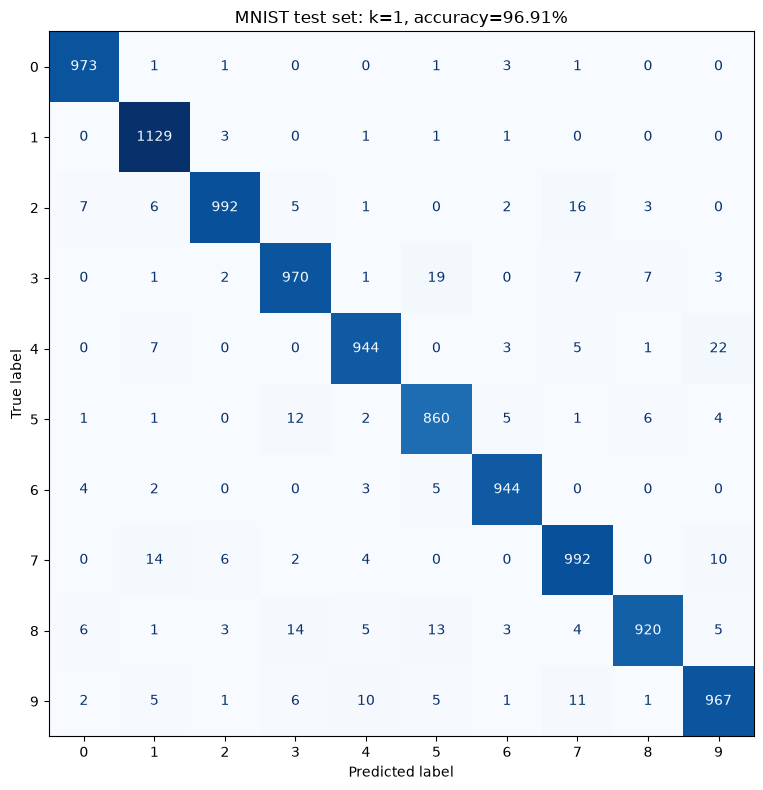

In [3]:
final_model = KNeighborsClassifier(
    n_neighbors=best_k, weights="uniform", metric="euclidean", algorithm="brute"
)
final_model.fit(X_train_flat, y_train)
with threadpool_limits(limits=2):
    test_predictions = final_model.predict(X_test_flat)
test_accuracy = accuracy_score(y_test, test_predictions)
cm = confusion_matrix(y_test, test_predictions, labels=np.arange(10))
correct = int(np.trace(cm))
incorrect = int(cm.sum() - correct)
assert cm.shape == (10, 10) and cm.sum() == len(y_test)
assert correct == np.count_nonzero(test_predictions == y_test)
print(f"Selected k: {best_k}")
print(f"Test accuracy: {test_accuracy:.4%}")
print(f"Correct: {correct:,}; incorrect: {incorrect:,}; total: {len(y_test):,}")
print("Confusion matrix (rows=actual, columns=predicted):\n", cm)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title(f"MNIST test set: k={best_k}, accuracy={test_accuracy:.2%}")
fig.tight_layout()
plt.show()

#### Question 6: Most frequent mistakes and digit-specific error rates

The top table ranks directed confusions by their raw counts. Per-class error rates also account for unequal numbers of test examples per digit. Similar handwriting shapes are a plausible explanation for confusion, but the confusion matrix alone does not establish its cause.

In [4]:
errors = cm.copy()
np.fill_diagonal(errors, 0)
ranked_pairs = sorted(
    [(int(errors[a, p]), a, p) for a in range(10) for p in range(10)
     if a != p and errors[a, p] > 0],
    key=lambda item: (-item[0], item[1], item[2])
)
print("Most frequent directed mistakes:")
print("Actual -> predicted | count | fraction of that actual digit")
for count, actual, predicted in ranked_pairs[:10]:
    print(f"{actual} -> {predicted}: {count:3d} ({count / cm[actual].sum():.2%})")
support = cm.sum(axis=1)
class_errors = support - np.diag(cm)
class_error_rates = class_errors / support
print("\nPer-digit error rates:")
for digit in range(10):
    print(f"{digit}: {class_errors[digit]}/{support[digit]} = {class_error_rates[digit]:.2%}")
most_reliable = int(np.argmin(class_error_rates))
least_reliable = int(np.argmax(class_error_rates))
print(f"Lowest error rate: digit {most_reliable}; highest: digit {least_reliable}")

Most frequent directed mistakes:
Actual -> predicted | count | fraction of that actual digit
4 -> 9:  22 (2.24%)
3 -> 5:  19 (1.88%)
2 -> 7:  16 (1.55%)
7 -> 1:  14 (1.36%)
8 -> 3:  14 (1.44%)
8 -> 5:  13 (1.33%)
5 -> 3:  12 (1.35%)
9 -> 7:  11 (1.09%)
7 -> 9:  10 (0.97%)
9 -> 4:  10 (0.99%)

Per-digit error rates:
0: 7/980 = 0.71%
1: 6/1135 = 0.53%
2: 40/1032 = 3.88%
3: 40/1010 = 3.96%
4: 38/982 = 3.87%
5: 32/892 = 3.59%
6: 14/958 = 1.46%
7: 36/1028 = 3.50%
8: 54/974 = 5.54%
9: 42/1009 = 4.16%
Lowest error rate: digit 1; highest: digit 8


#### Question 7: Color images as tabular data

Represent an RGB photo as an array of shape `(height, width, 3)`, with the final axis holding red, green, and blue intensities from 0 to 255 for an 8-bit image. A 28 × 28 RGB image contains 2,352 values. Flatten it in a consistent order, for example `rgb_image.reshape(-1)`, so columns correspond to `(row, column, channel)` positions. With N equally sized images, `rgb_images.reshape(N, 2352)` creates an N × 2,352 table. Keep each image's label in a separate length-N vector. Resize or pad photos to a common size before flattening; all images must use the same channel order and intensity scale.

**Limitations:** The selected k is best only among the eight candidates on this one validation split. Other splits, distance metrics, or weighted voting could change the choice. Raw-pixel kNN is sensitive to shifts and handwriting style and stores the training examples for prediction. This revision does not tune further after seeing the test results.

### *Reflection on AI assistance

AI coding is useful when working with basic computer vision tasks like kNN and the MNIST dataset. It can help us write code, understand algorithms, and fix errors. For example, we can use AI to load the MNIST dataset, train a kNN classifier, and predict handwritten digits. AI can also help us calculate accuracy and compare results using different values of k.

AI is especially helpful when we are unfamiliar with Python libraries like scikit-learn. It can explain how kNN works and why certain predictions are incorrect. It can also suggest ways to improve model performance.

However, we should not rely on AI for everything. We still need to understand the code and verify the results. We should also test different parameters ourselves. Overall, AI coding makes the learning process easier and faster. It helps us focus more on understanding computer vision concepts rather than writing repetitive code.